In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import libraries and define project paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Main internship folder
base_dir = Path("/content/drive/MyDrive/MVJ_Internship")

# Day 13 output folder
day13_dir = base_dir / "Project1" / "day13_customer_analytics"

# Day 15 project folder
day15_dir = base_dir / "Project2" / "day15_customer_segmentation"

# Create the Day 15 folder if it does not exist
day15_dir.mkdir(parents=True, exist_ok=True)

print("Day 13 folder exists:", day13_dir.exists())
print("Day 15 folder exists:", day15_dir.exists())
print("\nDay 13 files:")
if day13_dir.exists():
    for file in sorted(day13_dir.iterdir()):
        if file.is_file():
            print(file.name)

Day 13 folder exists: True
Day 15 folder exists: True

Day 13 files:
cohort_customer_counts.csv
cohort_retention_heatmap.png
cohort_retention_matrix.csv
customer_rfm_scores.csv
rfm_segment_summary.csv


In [ ]:
# Verify the four required Day 13 outputs

required_files = [
    "customer_rfm_scores.csv",
    "rfm_segment_summary.csv",
    "cohort_retention_matrix.csv",
    "cohort_retention_heatmap.png"
]

print("Checking Day 13 outputs:\n")

for filename in required_files:
    file_path = day13_dir / filename

    if file_path.exists():
        print("FOUND:", filename)
    else:
        print("MISSING:", filename)

Checking Day 13 outputs:

FOUND: customer_rfm_scores.csv
FOUND: rfm_segment_summary.csv
FOUND: cohort_retention_matrix.csv
FOUND: cohort_retention_heatmap.png


In [ ]:
# Load the Day 13 analysis files
rfm = pd.read_csv(day13_dir / "customer_rfm_scores.csv")
segment_summary = pd.read_csv(day13_dir / "rfm_segment_summary.csv")
cohort_retention = pd.read_csv(day13_dir / "cohort_retention_matrix.csv")

# Display dataset dimensions
print("RFM data shape:", rfm.shape)
print("Segment summary shape:", segment_summary.shape)
print("Cohort retention shape:", cohort_retention.shape)

# Display column names
print("\nRFM columns:")
print(rfm.columns.tolist())

print("\nSegment summary columns:")
print(segment_summary.columns.tolist())

print("\nCohort retention columns:")
print(cohort_retention.columns.tolist())

# Display first five rows
display(rfm.head())
display(segment_summary.head())
display(cohort_retention.head())

RFM data shape: (5878, 10)
Segment summary shape: (6, 6)
Cohort retention shape: (25, 26)

RFM columns:
['Customer ID', 'Last_Purchase', 'Frequency', 'Monetary', 'Recency', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Segment']

Segment summary columns:
['Segment', 'Customers', 'Total_Revenue', 'Average_Recency_Days', 'Average_Frequency', 'Revenue_Share_Pct']

Cohort retention columns:
['CohortMonth', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25']


,Customer ID,Last_Purchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,2011-01-18,12,77556.46,326,2,5,5,255,At-Risk Customers
1,12347.0,2011-12-07,8,4921.53,3,5,4,5,545,High-Value Loyal
2,12348.0,2011-09-25,5,2019.40,76,3,4,4,344,Frequent Customers
3,12349.0,2011-11-21,4,4428.69,19,5,3,5,535,Recent and Active
4,12350.0,2011-02-02,1,334.40,311,2,1,2,212,Other Customers


,Segment,Customers,Total_Revenue,Average_Recency_Days,Average_Frequency,Revenue_Share_Pct
0,High-Value Loyal,1289,1.183075e+07,20.207913,17.147401,68.09
1,Frequent Customers,525,1.721600e+06,106.043810,8.558095,9.91
2,At-Risk Customers,824,1.589703e+06,369.641990,4.940534,9.15
3,Other Customers,2178,1.199559e+06,354.593664,1.505510,6.90
4,Recent and Active,621,6.411399e+05,24.780998,3.830918,3.69


,CohortMonth,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,2009-12,100.0,35.29,33.40,42.51,38.01,35.92,37.70,34.24,33.61,...,30.26,26.28,30.26,28.27,25.97,25.55,31.52,30.47,40.73,19.69
1,2010-01,100.0,20.63,31.07,30.55,26.37,30.03,25.85,22.98,27.94,...,15.14,23.50,19.84,18.54,19.58,24.28,19.32,24.54,5.74,NaN
2,2010-02,100.0,23.80,22.46,29.14,24.60,20.05,19.25,28.61,25.40,...,20.05,16.04,16.31,14.44,22.99,22.99,16.31,5.88,NaN,NaN
3,2010-03,100.0,18.96,23.02,24.15,23.25,20.32,24.60,30.25,27.54,...,16.93,17.38,15.58,17.61,20.09,21.22,7.90,NaN,NaN,NaN
4,2010-04,100.0,19.39,19.39,16.33,18.37,22.45,27.55,26.19,10.54,...,15.65,13.95,14.97,18.03,22.45,5.78,NaN,NaN,NaN,NaN


In [ ]:
#check missing values

print("Missing values in RFM data:")
display(rfm.isnull().sum())

print("\nMissing values in segment summary:")
display(segment_summary.isnull().sum())

print("\nMissing values in cohort retention:")
display(cohort_retention.isnull().sum())

Missing values in RFM data:


,0
Customer ID,0
Last_Purchase,0
Frequency,0
Monetary,0
Recency,0
R_Score,0
F_Score,0
M_Score,0
RFM_Score,0
Segment,0



Missing values in segment summary:


,0
Segment,0
Customers,0
Total_Revenue,0
Average_Recency_Days,0
Average_Frequency,0
Revenue_Share_Pct,0



Missing values in cohort retention:


,0
CohortMonth,0
1,0
2,1
3,2
4,3
5,4
6,5
7,6
8,7
9,8


In [ ]:
#display segment summary

display(segment_summary)

,Segment,Customers,Total_Revenue,Average_Recency_Days,Average_Frequency,Revenue_Share_Pct
0,High-Value Loyal,1289,1.183075e+07,20.207913,17.147401,68.09
1,Frequent Customers,525,1.721600e+06,106.043810,8.558095,9.91
2,At-Risk Customers,824,1.589703e+06,369.641990,4.940534,9.15
3,Other Customers,2178,1.199559e+06,354.593664,1.505510,6.90
4,Recent and Active,621,6.411399e+05,24.780998,3.830918,3.69
5,New or Promising,441,3.920216e+05,28.510204,1.462585,2.26


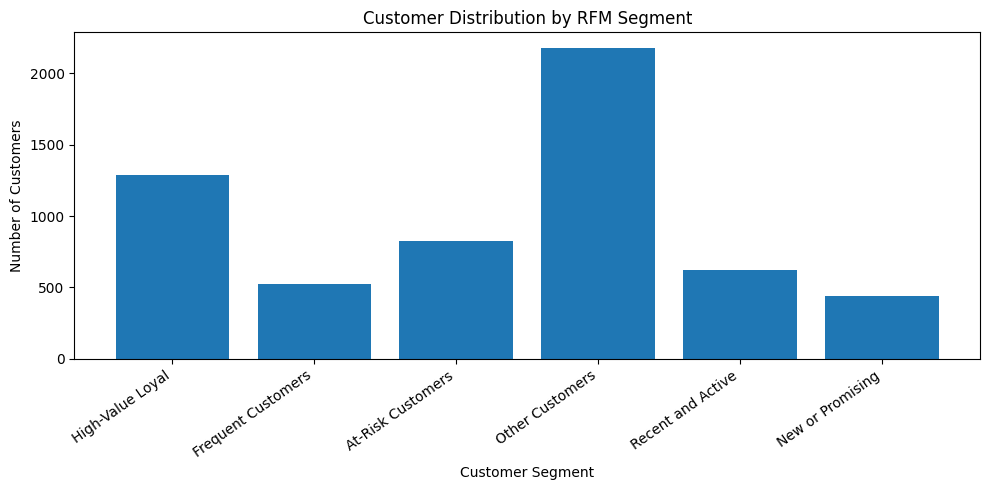

In [ ]:
# Create a bar chart of customer counts by segment

plt.figure(figsize=(10, 5))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Customers"]
)

plt.title("Customer Distribution by RFM Segment")

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#analyse customer value by segment

display(segment_summary)

,Segment,Customers,Total_Revenue,Average_Recency_Days,Average_Frequency,Revenue_Share_Pct
0,High-Value Loyal,1289,1.183075e+07,20.207913,17.147401,68.09
1,Frequent Customers,525,1.721600e+06,106.043810,8.558095,9.91
2,At-Risk Customers,824,1.589703e+06,369.641990,4.940534,9.15
3,Other Customers,2178,1.199559e+06,354.593664,1.505510,6.90
4,Recent and Active,621,6.411399e+05,24.780998,3.830918,3.69
5,New or Promising,441,3.920216e+05,28.510204,1.462585,2.26


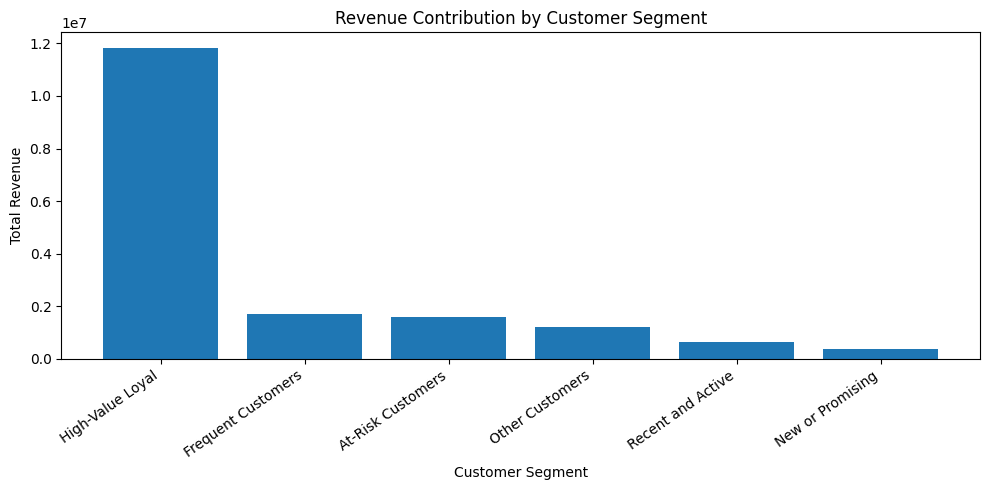

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Total_Revenue"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Analyse Cohort retention

In [ ]:
display(cohort_retention)

,CohortMonth,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,2009-12,100.0,35.29,33.40,42.51,38.01,35.92,37.70,34.24,33.61,...,30.26,26.28,30.26,28.27,25.97,25.55,31.52,30.47,40.73,19.69
1,2010-01,100.0,20.63,31.07,30.55,26.37,30.03,25.85,22.98,27.94,...,15.14,23.50,19.84,18.54,19.58,24.28,19.32,24.54,5.74,NaN
2,2010-02,100.0,23.80,22.46,29.14,24.60,20.05,19.25,28.61,25.40,...,20.05,16.04,16.31,14.44,22.99,22.99,16.31,5.88,NaN,NaN
3,2010-03,100.0,18.96,23.02,24.15,23.25,20.32,24.60,30.25,27.54,...,16.93,17.38,15.58,17.61,20.09,21.22,7.90,NaN,NaN,NaN
4,2010-04,100.0,19.39,19.39,16.33,18.37,22.45,27.55,26.19,10.54,...,15.65,13.95,14.97,18.03,22.45,5.78,NaN,NaN,NaN,NaN
5,2010-05,100.0,15.75,16.93,17.32,17.72,25.59,21.26,12.60,5.91,...,12.60,13.78,16.54,15.35,4.72,NaN,NaN,NaN,NaN,NaN
6,2010-06,100.0,17.41,18.89,20.37,22.96,28.52,12.59,8.89,8.15,...,12.22,13.33,20.37,5.19,NaN,NaN,NaN,NaN,NaN,NaN
7,2010-07,100.0,15.59,18.28,29.57,29.03,13.98,11.29,14.52,14.52,...,17.20,23.66,8.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2010-08,100.0,20.37,29.63,32.10,17.28,11.73,9.88,12.35,13.58,...,19.75,6.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2010-09,100.0,22.63,23.46,12.35,9.05,10.29,13.58,9.88,12.76,...,5.35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


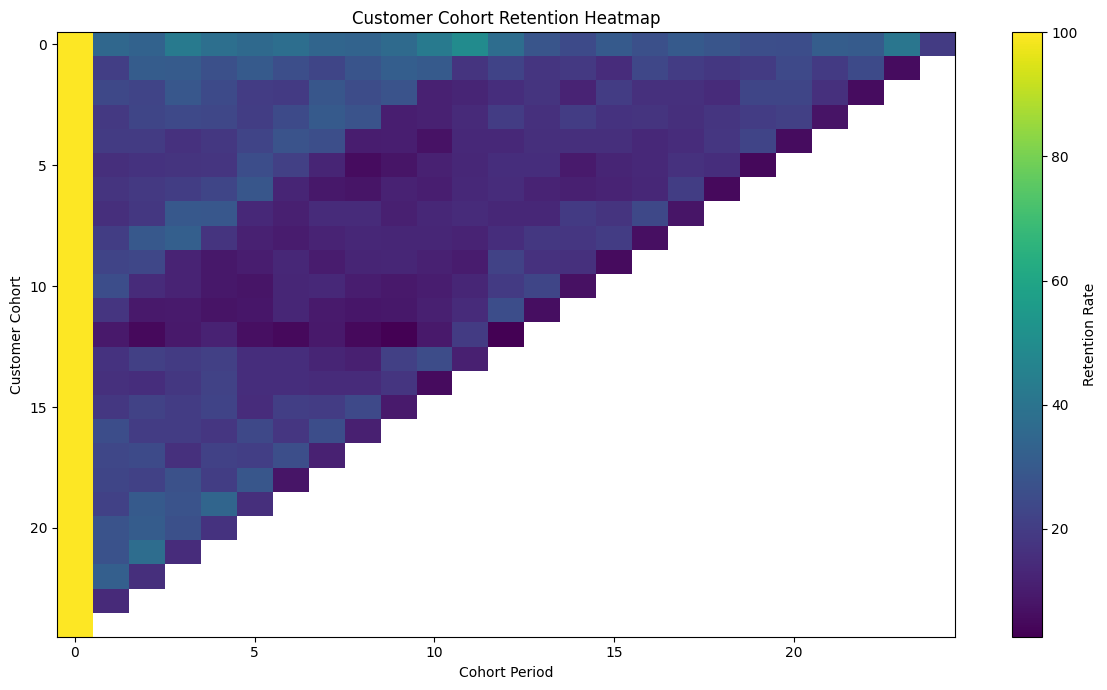

In [ ]:
#create a heatmap

plt.figure(figsize=(12, 7))

plt.imshow(
    cohort_retention.select_dtypes(include="number"),
    aspect="auto"
)

plt.colorbar(label="Retention Rate")
plt.title("Customer Cohort Retention Heatmap")
plt.xlabel("Cohort Period")
plt.ylabel("Customer Cohort")
plt.tight_layout()
plt.show()

Customer Segment Analysis

1. Largest customer segment:OTHER CUSTOMERS
2. Highest revenue-generating segment: HIGH-VALUE CUSTOMERS
3. Segment showing retention concerns:
4. Segment selected for the first retention campaign:
5. Reason for selecting this segment:

In [ ]:
retention_plan = """
# Customer Retention Plan

## Project Objective
Improve customer retention using RFM segmentation and cohort analysis.

## Key Findings
[Insert your actual findings]

## Target Segment
[Insert your selected segment and reason]

## Recommended Strategies
[Insert your retention strategies]

## Success Measurement
- Customer retention rate
- Repeat purchase rate
- Customer churn rate
- Revenue from targeted segment
- Campaign conversion rate

## Expected Outcome
Improve repeat purchases and reduce customer inactivity.
"""

with open(day15_dir / "customer_retention_plan.md", "w") as file:
    file.write(retention_plan)

print("Retention plan template saved.")

Retention plan template saved.


In [ ]:
#SAVE PROJECT2 OUTPUTS

# Save copies of the analysis files in Project 2
rfm.to_csv(day15_dir / "customer_rfm_scores.csv", index=False)

segment_summary.to_csv(
    day15_dir / "rfm_segment_summary.csv",
    index=False
)

cohort_retention.to_csv(
    day15_dir / "cohort_retention_matrix.csv"
    , index=True
)

print("Project 2 analysis files saved successfully.")

Project 2 analysis files saved successfully.


In [ ]:
#final project verification
print("PROJECT 2 OUTPUT FILES")

for file in sorted(day15_dir.iterdir()):
    print(file.name)

PROJECT 2 OUTPUT FILES
cohort_retention_matrix.csv
customer_retention_plan.md
customer_rfm_scores.csv
rfm_segment_summary.csv
